# 📘 Notebook 06: Sequence to Sequence, and the Birth of Attention

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Papers: Sutskever, Vinyals and Le (2014) · Cho et al. (2014) · Bahdanau, Cho and Bengio (2014)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** Two small encoder-decoder networks (96 units each) learn to **reverse sequences of digits** for 2,500 steps: about **eight minutes** in total on a laptop processor (the attention model is the slower one, about five minutes). The papers translated English to French with networks of 1,000 units and four layers, trained for days on GPUs; we use a synthetic task so that the effect of attention is visible in minutes and every alignment can be checked by eye. The decoder of a real translator also uses a **beam search**; we use the simpler greedy decoding. Results vary slightly between runs and machines.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain the **encoder-decoder** (sequence to sequence) architecture and **teacher forcing**
- Explain the **bottleneck** of squeezing a whole input sequence into one fixed vector
- Explain **attention**: at each output step, a weighted look back over **all** input positions
- Build both models in PyTorch and measure how their accuracy changes with **sequence length**
- Read an **attention map** and see what the network looks at

> **Prerequisites:** [Notebook 05: LSTM](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/05_lstm.ipynb). Machine translation with attention is applied to text in [From Words to Meaning](https://giannis00.github.io/teaching/#nlp).
>
> 🔭 **Why this notebook matters:** sequence-to-sequence models gave the world neural machine translation (Google Translate switched to them in 2016). Attention, added to fix their bottleneck, turned out to be far more than a fix: three years later it became the **only** mechanism of the Transformer (Notebook 07), and therefore of every modern language model.

## 1. The papers

> 📄 I. Sutskever, O. Vinyals and Q. V. Le, [*Sequence to Sequence Learning with Neural Networks*](https://arxiv.org/abs/1409.3215), NeurIPS 2014.
>
> 📄 K. Cho et al., [*Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation*](https://arxiv.org/abs/1406.1078), EMNLP 2014 (which also introduced the GRU).
>
> 📄 D. Bahdanau, K. Cho and Y. Bengio, [*Neural Machine Translation by Jointly Learning to Align and Translate*](https://arxiv.org/abs/1409.0473), ICLR 2015 (arXiv 2014).

### Intuition first
To translate a sentence, a network must read a sequence and **write** another one, of a different length. The **encoder-decoder** splits the job:
- an **encoder** RNN reads the input and ends with a final hidden state, a single vector meant to summarise the whole sentence;
- a **decoder** RNN starts from that vector and writes the output one word at a time, feeding each word it writes back in as the next input.

During training the decoder is fed the **correct** previous word instead of its own guess (**teacher forcing**), which makes learning much faster.

Bahdanau and colleagues noticed the weak point: every sentence, short or long, must pass through **one fixed-size vector**. Long sentences do not fit. Their fix: let the decoder, at every step, look back at **all** the encoder's states, compute a **score** for each (how relevant is input position *j* for what I am writing now?), turn the scores into weights with a softmax, and use the weighted average as extra input. This weighted look-back is **attention**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__)

PyTorch 2.2.2+cpu


## 2. The task: reverse a sequence of digits

Input: a random sequence of 3 to 20 digits. Output: the same digits in **reverse** order, followed by an end symbol. Reversal is a good test because the **first** output digit is the **last** input digit, and the last output is the very first input: the decoder needs exact information from every position.

In [2]:
DIGITS, SOS, EOS, PAD = 10, 10, 11, 12
VOCAB = 13

def make_batch(n, shortest, longest):
    lengths = [random.randint(shortest, longest) for _ in range(n)]
    width = max(lengths)
    src = torch.full((n, width), PAD)
    tgt = torch.full((n, width + 1), PAD)
    for i, length in enumerate(lengths):
        seq = torch.randint(0, DIGITS, (length,))
        src[i, :length] = seq
        tgt[i, :length] = seq.flip(0)
        tgt[i, length] = EOS
    return src, tgt

random.seed(1)
src, tgt = make_batch(2, 5, 8)
print("input :", src.tolist())
print("target:", tgt.tolist(), "  (11 = end, 12 = padding)")

input : [[2, 4, 1, 9, 3, 2], [3, 2, 2, 0, 5, 12]]
target: [[2, 3, 9, 1, 4, 2, 11], [5, 0, 2, 2, 3, 11, 12]]   (11 = end, 12 = padding)


## 3. The two models

Both models share the same encoder (a GRU, Notebook 05) and decoder. The only difference: the attention model computes, at every output step, the scores over all encoder states (Bahdanau's additive score $v^\top \tanh(W h_{dec} + U h_{enc})$) and feeds the weighted average to the decoder.

In [3]:
class Seq2Seq(nn.Module):
    def __init__(self, attention, hidden=96):
        super().__init__()
        self.attention = attention
        self.embed = nn.Embedding(VOCAB, 32)
        self.encoder = nn.GRU(32, hidden, batch_first=True)
        self.decoder = nn.GRUCell(32 + (hidden if attention else 0), hidden)
        self.W = nn.Linear(hidden, hidden, bias=False)
        self.U = nn.Linear(hidden, hidden)
        self.v = nn.Linear(hidden, 1, bias=False)
        self.out = nn.Linear(hidden * (2 if attention else 1), VOCAB)

    def forward(self, src, steps, teacher=None):
        lengths = (src != PAD).sum(1)
        packed = nn.utils.rnn.pack_padded_sequence(self.embed(src), lengths, batch_first=True, enforce_sorted=False)
        states, last = self.encoder(packed)          # packing: the encoder stops at each sequence's real end
        states, _ = nn.utils.rnn.pad_packed_sequence(states, batch_first=True, total_length=src.size(1))
        mask = src != PAD
        h = last[0]                                  # the single summary vector
        keys = self.U(states)
        token = torch.full((src.size(0),), SOS)
        outputs, weights = [], []
        for t in range(steps):
            e = self.embed(token)
            if self.attention:
                score = self.v(torch.tanh(self.W(h)[:, None] + keys)).squeeze(2).masked_fill(~mask, -1e9)
                a = score.softmax(1)                   # one weight per input position
                context = (a[:, :, None] * states).sum(1)
                h = self.decoder(torch.cat([e, context], 1), h)
                logits = self.out(torch.cat([h, context], 1))
                weights.append(a)
            else:
                h = self.decoder(e, h)
                logits = self.out(h)
            outputs.append(logits)
            token = teacher[:, t] if teacher is not None else logits.argmax(1)
        return torch.stack(outputs, 1), (torch.stack(weights, 1) if weights else None)

count = lambda m: sum(p.numel() for p in m.parameters())
print("weights: without attention", f"{count(Seq2Seq(False)):,}", "  with attention", f"{count(Seq2Seq(True)):,}")

weights: without attention 95,181   with attention 124,077


**What we see.** Attention adds about **30%** more weights (124,077 against 95,181): the score parameters $W$, $U$, $v$ and a wider output layer. That is a modest cost; Section 4 shows what it buys.

## 4. Training, and accuracy by length

Both models train on sequences of 3 to 20 digits. We then test them on fixed lengths from 4 to 24; length 24 is **longer** than anything seen in training. We report **exact** accuracy (the whole reversed sequence correct, including the end symbol) and **digit** accuracy (share of correct output digits).

In [4]:
def train(attention, steps=2500):
    torch.manual_seed(0); random.seed(0)
    model = Seq2Seq(attention)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    start = time.time()
    for _ in range(steps):
        src, tgt = make_batch(64, 3, 20)
        logits, _ = model(src, tgt.size(1), teacher=tgt)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    print(f"{'with' if attention else 'without'} attention: trained in {time.time() - start:.0f} s")
    return model

def evaluate(model, lengths=(4, 8, 12, 16, 20, 24), n=300):
    random.seed(123); torch.manual_seed(123)
    rows = {}
    with torch.no_grad():
        for length in lengths:
            src, tgt = make_batch(n, length, length)
            pred = model(src, tgt.size(1))[0].argmax(2)
            rows[length] = ((pred == tgt).all(1).float().mean().item(), (pred == tgt)[:, :length].float().mean().item())
    return rows

plain = train(False)
attn = train(True)
table = {}
for name, model in [("without attention", plain), ("with attention", attn)]:
    for length, (exact, digit) in evaluate(model).items():
        table.setdefault(length, {})[f"{name}: exact"] = exact
        table[length][f"{name}: digits"] = digit
import pandas as pd
pd.DataFrame(table).T.rename_axis("length").round(3)

without attention: trained in 194 s


with attention: trained in 306 s


,without attention: exact,without attention: digits,with attention: exact,with attention: digits
length,,,,
4,0.997,0.999,0.990,0.997
8,0.950,0.988,0.983,0.998
12,0.617,0.891,0.947,0.983
16,0.083,0.673,0.923,0.973
20,0.000,0.486,0.910,0.970
24,0.000,0.364,0.860,0.948


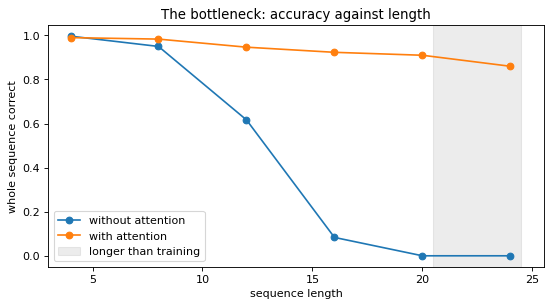

In [5]:
lengths = list(table)
plt.figure(figsize=(8, 4))
plt.plot(lengths, [table[l]["without attention: exact"] for l in lengths], marker="o", label="without attention")
plt.plot(lengths, [table[l]["with attention: exact"] for l in lengths], marker="o", label="with attention")
plt.axvspan(20.5, 24.5, color="grey", alpha=0.15, label="longer than training")
plt.xlabel("sequence length")
plt.ylabel("whole sequence correct")
plt.legend()
plt.title("The bottleneck: accuracy against length")
plt.show()

**What we see.** The bottleneck, measured:
- **Without attention**, the model is nearly perfect on short sequences (**99.7%** of 4-digit and **95%** of 8-digit sequences reversed exactly), then collapses: **62%** at 12 digits, **8%** at 16 and **0%** at 20, although 20-digit sequences were in its training data. Its digit accuracy at 20 is still **49%**: it gets the first digits it writes (the last ones it read) right and loses track of the rest.
- **With attention**, exact accuracy falls only gently: **95%** at 12 digits, **92%** at 16, **91%** at 20, and still **86%** at 24 digits, a length it has never seen.

One vector of 96 numbers can carry about a dozen digits exactly; beyond that, information is lost. Attention avoids the limit by reading the encoder's states directly whenever they are needed.

## 5. What does attention look at?

input  : 5 2 1 6 3 7 7 9 8 1 8 1
output : 1 8 1 8 9 7 7 3 6 1 2 5 end


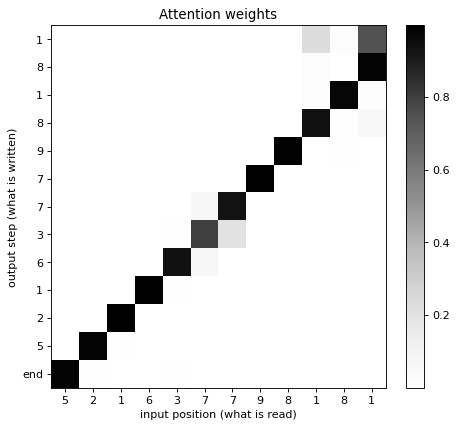

In [6]:
random.seed(7); torch.manual_seed(7)
src, tgt = make_batch(1, 12, 12)
with torch.no_grad():
    logits, weights = attn(src, tgt.size(1))
pred = logits.argmax(2)[0].tolist()
labels_in = [str(d) for d in src[0].tolist()]
labels_out = [str(d) if d < 10 else "end" for d in pred]
print("input  :", " ".join(labels_in))
print("output :", " ".join(labels_out))
plt.figure(figsize=(6.5, 6))
plt.imshow(weights[0].numpy(), cmap="Greys")
plt.xticks(range(len(labels_in)), labels_in)
plt.yticks(range(len(labels_out)), labels_out)
plt.xlabel("input position (what is read)")
plt.ylabel("output step (what is written)")
plt.title("Attention weights")
plt.colorbar(fraction=0.046)
plt.show()

**What we see.** The input was `5 2 1 6 3 7 7 9 8 1 8 1` and the model wrote the correct reversal, `1 8 1 8 9 7 7 3 6 1 2 5`, then *end*. Each row shows where the decoder looked while writing one output digit. The dark cells form a clean **anti-diagonal**: to write its first digit it looks at the last input position, to write its second the one before, and so on. Nobody told the model that reversal means "read backwards"; it learned this **alignment** from the examples alone, exactly the behaviour Bahdanau and colleagues showed for French and English word order. Where the input has two identical neighbours (the two 7s), the attention spreads over both, which is harmless because either gives the right digit.

## ⚠️ Common pitfalls

- **Letting the encoder read padding.** In a batch of different lengths, short sequences are padded; without **packing** (or masking), the final state also summarises the padding. An early version of this very notebook made that mistake, and the model without attention looked far worse than it really is.
- **Forgetting to mask attention.** Padding positions must get a score of minus infinity before the softmax, or the decoder will attend to them.
- **Evaluating with teacher forcing.** At test time the decoder must feed back **its own** predictions; teacher forcing would give it the answers.
- **Reporting only digit accuracy.** A model can get most digits right and almost no whole sequence right; for translation, both views matter.
- **Expecting generalisation to unseen lengths.** Neither model was trained on 24 digits, and both suffer there.

## ✏️ Exercises

### Exercise 1 (Copy instead of reverse)
Change the task to **copying** the sequence (remove `.flip(0)` in a new `make_batch`), and train only the model **without** attention. Is copying easier or harder than reversing for it? Why might that be?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def make_copy_batch(n, shortest, longest):
    src, tgt = make_batch(n, shortest, longest)
    for i in range(n):
        length = int((src[i] != PAD).sum())
        tgt[i, :length] = src[i, :length]
    return src, tgt

torch.manual_seed(0); random.seed(0)
copier = Seq2Seq(False)
opt = torch.optim.Adam(copier.parameters(), lr=2e-3)
for _ in range(2500):
    s, t = make_copy_batch(64, 3, 20)
    loss = F.cross_entropy(copier(s, t.size(1), teacher=t)[0].reshape(-1, VOCAB), t.reshape(-1), ignore_index=PAD)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(copier.parameters(), 1.0); opt.step()
random.seed(123)
s, t = make_copy_batch(300, 12, 12)
with torch.no_grad():
    print("copy, length 12, exact:", round((copier(s, t.size(1))[0].argmax(2) == t).all(1).float().mean().item(), 3))
```

*For a model without attention, **reversing** is usually easier: the first digit it must write is the last one it read, still fresh in the summary vector. Copying needs the first digit, read longest ago. Sutskever et al. found the same thing and fed their source sentences **in reverse** to make translation easier, a trick that attention made unnecessary.*
</details>

### Exercise 2 (A longer test)
Evaluate both trained models on lengths 28 and 32. What happens to the attention model, and what does that say about training data?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for name, model in [("without attention", plain), ("with attention", attn)]:
    print(name, {l: round(e, 3) for l, (e, d) in evaluate(model, lengths=(28, 32)).items()})
```

*Both models fail on much longer sequences. Attention removes the bottleneck, but the network has never written a 28th output digit, so its decoder does not know how to continue. Models generalise poorly outside the range of their training data.*
</details>

### Exercise 3 (Where is the model unsure?)
For the attention model, find the output step where the attention is **least** concentrated (the lowest maximum weight) in the example of Section 5. Which input positions does it spread over?

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
w = weights[0]
step = int(w.max(1).values.argmin())
top = w[step].topk(3)
print("least focused output step:", step, "  max weight:", round(w[step].max().item(), 3))
print("top input positions:", top.indices.tolist(), " weights:", [round(x, 3) for x in top.values.tolist()])
```

*The least focused steps are usually the end symbol (the decoder looks around to check that it has used every digit) or a position next to a repeated digit, where two input positions look alike.*
</details>

## 🔑 Key takeaways

- An **encoder-decoder** reads one sequence and writes another; **teacher forcing** speeds up training.
- Without attention, the whole input must pass through **one vector**, and accuracy falls as sequences get longer.
- **Attention** lets the decoder look back at **every** input position with learned weights; for reversal it learns the reverse alignment on its own.
- Attention maps make a network's behaviour **visible**.
- Implementation details (packing, masking) can change a comparison completely; check them before trusting a result.

---
**Next:** *Notebook 07: The Transformer*, which asks: if attention is so useful, do we need the recurrent network at all?

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*